# 03 · Q is for Quantum: balls, boxes & mist ⚪⚫☁️
### Quantum Technologies Club Workshop · *Qiskit from zero*

This notebook uses the **"Q is for Quantum"** picture of quantum computing (from Terry Rudolph's book *Q is for Quantum* and the *Quantum Abacus* teaching approach): coloured balls going through boxes. Every step is **real Qiskit code**.

The rules of the game:

| Ball game | Qiskit | Meaning |
|---|---|---|
| ○ white ball | `0` | qubit in state \|0⟩ |
| ● black ball | `1` | qubit in state \|1⟩ |
| a **box** on a wire | a **gate** | does something to the balls |
| ☁️ **mist** of possibilities | **superposition** | the qubit is "all of these at once" until we look |

**Wires are drawn top → bottom = qubit 0, 1, 2…** and our ball strings read in the same order (left ball = top wire = qubit 0).

In [1]:
# ⚙️ SETUP: run this cell first (Shift + Enter)
# On Google Colab (or any fresh computer) this installs Qiskit automatically. Takes ~30 s the first time.
try:
    import qiskit, qiskit_aer, qiskit_ibm_runtime
except ImportError:
    %pip install -q qiskit qiskit-aer qiskit-ibm-runtime pylatexenc matplotlib ipywidgets
    import qiskit, qiskit_aer, qiskit_ibm_runtime

import numpy as np
import matplotlib.pyplot as plt
print("✅ Qiskit", qiskit.__version__, "| Aer", qiskit_aer.__version__, "| ready to go!")

✅ Qiskit 2.6.2 | Aer 0.18.2 | ready to go!


In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram, plot_bloch_multivector, plot_state_qsphere
from qiskit_aer.primitives import SamplerV2 as Sampler
from IPython.display import Markdown

sampler = Sampler()

# ---------- 🧰 ball helpers (just run this) ----------
def balls(bits_q0_first):
    """'01' (q0, q1) -> '○●'"""
    return "".join("○" if b == "0" else "●" for b in bits_q0_first)

def qiskit_to_balls(bitstring):
    """Qiskit writes qubit 0 on the RIGHT; flip so the top wire comes first."""
    return balls(bitstring[::-1])

def mist(qc):
    """Describe a circuit's state as a 'mist' of ball configurations."""
    sv = Statevector(qc)
    terms = []
    for idx, amp in enumerate(sv.data):
        if abs(amp) > 1e-9:
            bits = format(idx, f"0{qc.num_qubits}b")       # Qiskit order
            sign = "−" if np.real(amp) < -1e-9 else "+"
            terms.append((sign, qiskit_to_balls(bits)))
    if len(terms) == 1:
        return f"**{terms[0][1]}**" + ("  (with a hidden − sign)" if terms[0][0] == "−" else "")
    body = " , ".join((s if s == "−" else "") + b for s, b in terms)
    return f"☁️ mist of {{ **{body}** }}"

def show_mist(qc, label=""):
    display(Markdown(f"{label} {mist(qc)}"))

def truth_table(gate_circuit):
    """Feed every possible combination of balls into a box and show what comes out."""
    n = gate_circuit.num_qubits
    rows = ["| in | → | out |", "|:-:|:-:|:-:|"]
    for i in range(2 ** n):
        inp = format(i, f"0{n}b")                  # input pattern, q0 first
        qc = QuantumCircuit(n)
        for q, b in enumerate(inp):
            if b == "1":
                qc.x(q)
        qc.compose(gate_circuit, inplace=True)
        rows.append(f"| {balls(inp)} | → | {mist(qc)} |")
    display(Markdown("\n".join(rows)))

def ball_histogram(qc, shots=1000, title=None):
    meas = qc.measure_all(inplace=False)
    counts = sampler.run([meas], shots=shots).result()[0].data.meas.get_counts()
    nice = {qiskit_to_balls(k): v for k, v in sorted(counts.items())}
    fig = plot_histogram(nice, title=title, figsize=(max(5, 1.3 * len(nice)), 3.5))
    for lbl in fig.axes[0].get_xticklabels():
        lbl.set_rotation(0); lbl.set_fontsize(18)
    return fig

print("Ball helpers ready ✅  e.g. balls('01') =", balls("01"))

Ball helpers ready ✅  e.g. balls('01') = ○●


## 1 · The NOT box (X gate)
The simplest box: whatever colour goes in, the **opposite** colour comes out.

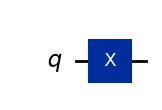

| in | → | out |
|:-:|:-:|:-:|
| ○ | → | **●** |
| ● | → | **○** |

In [3]:
NOT = QuantumCircuit(1)
NOT.x(0)
display(NOT.draw("mpl"))
truth_table(NOT)

## 2 · The C-NOT box (controlled-NOT, `cx`)
Two wires. The ball on the **control** wire (the dot ●) decides:
* control is ○ → do nothing to the target
* control is ● → apply NOT to the **target** (the ⊕)

The control ball itself never changes.

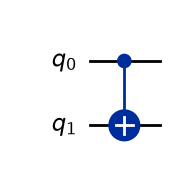

| in | → | out |
|:-:|:-:|:-:|
| ○○ | → | **○○** |
| ○● | → | **○●** |
| ●○ | → | **●●** |
| ●● | → | **●○** |

In [4]:
CNOT = QuantumCircuit(2)
CNOT.cx(0, 1)          # control = qubit 0 (top), target = qubit 1 (bottom)
display(CNOT.draw("mpl"))
truth_table(CNOT)

## 3 · The SWAP box… built from C-NOTs 🔀
SWAP exchanges two balls. Here's a neat trick: **three C-NOTs in a row (alternating direction) make a SWAP**. Let's check both the truth table *and* ask Qiskit if the two boxes are mathematically identical:

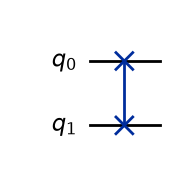

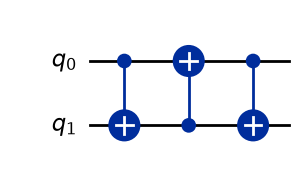

| in | → | out |
|:-:|:-:|:-:|
| ○○ | → | **○○** |
| ○● | → | **●○** |
| ●○ | → | **○●** |
| ●● | → | **●●** |

Are they the same box? True


In [5]:
SWAP = QuantumCircuit(2)
SWAP.swap(0, 1)

three_cnots = QuantumCircuit(2)
three_cnots.cx(0, 1)
three_cnots.cx(1, 0)
three_cnots.cx(0, 1)

display(SWAP.draw("mpl"), three_cnots.draw("mpl"))
truth_table(three_cnots)
print("Are they the same box?", Operator(SWAP).equiv(Operator(three_cnots)))

## 4 · The C-SWAP box (Fredkin gate)
Three wires: if the **control** (top) is ●, swap the other two; if it's ○, leave them alone.

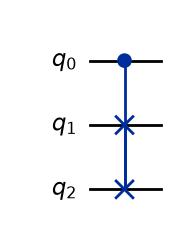

| in | → | out |
|:-:|:-:|:-:|
| ○○○ | → | **○○○** |
| ○○● | → | **○○●** |
| ○●○ | → | **○●○** |
| ○●● | → | **○●●** |
| ●○○ | → | **●○○** |
| ●○● | → | **●●○** |
| ●●○ | → | **●○●** |
| ●●● | → | **●●●** |

In [6]:
CSWAP = QuantumCircuit(3)
CSWAP.cswap(0, 1, 2)      # control = qubit 0, swap qubits 1 and 2
display(CSWAP.draw("mpl"))
truth_table(CSWAP)

So far everything is **classical**: balls in, balls out, no surprises. You could build all of this with marbles and wooden boxes.
Now for the **quantum magic** box. 🪄

## 5 · The Hadamard box (H): making mist
Put a ○ into the H box and what comes out is a **mist** of ○ and ●: the qubit is in *both* configurations at once. If you look, you find ○ or ● at random (50/50).

Put a ● in and you also get a mist of ○ and ●… but with a **minus sign** on the ●. You can't see the sign by looking, it is *hidden*.

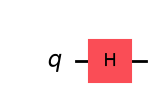

| in | → | out |
|:-:|:-:|:-:|
| ○ | → | ☁️ mist of { **○ , ●** } |
| ● | → | ☁️ mist of { **○ , −●** } |

In [7]:
H = QuantumCircuit(1)
H.h(0)
display(H.draw("mpl"))
truth_table(H)

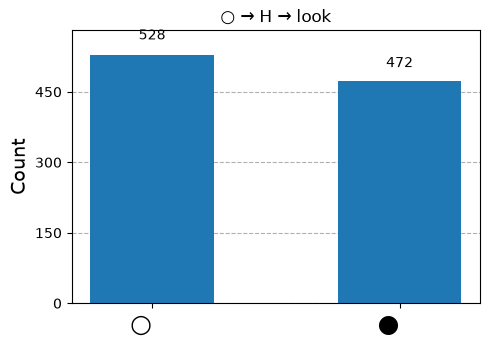

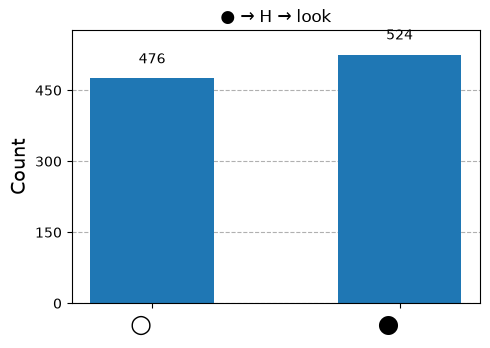

In [8]:
# Looking at the two mists gives the SAME statistics: the minus sign is invisible
white_in = QuantumCircuit(1); white_in.h(0)
black_in = QuantumCircuit(1); black_in.x(0); black_in.h(0)
display(ball_histogram(white_in, title="○ → H → look"), ball_histogram(black_in, title="● → H → look"))

### Two H boxes in a row 🎩🐇
If the minus sign is invisible, does it matter? **Yes!** Send a ball through **two** H boxes:

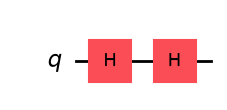

| in | → | out |
|:-:|:-:|:-:|
| ○ | → | **○** |
| ● | → | **●** |

In [9]:
HH = QuantumCircuit(1)
HH.h(0)
HH.h(0)
display(HH.draw("mpl"))
truth_table(HH)

The mist **un-mists**: you always get back exactly what you put in. Inside the second box, the ○ and ● possibilities meet, and the minus sign makes some of them **cancel out** (interference, which you saw in notebook 02). Mist is not just "we don't know which": it's a genuinely new kind of thing.

## 6 · Entanglement: the Bell state 🔗
Now combine a mist-maker with a C-NOT:
1. `H` on the top ball → mist { ○ , ● }
2. `CNOT` from top to bottom → the bottom ball flips **only in the ● part of the mist**

After H: ☁️ mist of { **○○ , ●○** }

After CNOT: ☁️ mist of { **○○ , ●●** }

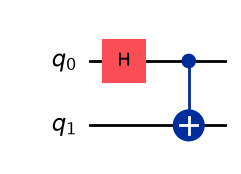

In [10]:
bell = QuantumCircuit(2)
bell.h(0)
show_mist(bell, "After H:")
bell.cx(0, 1)
show_mist(bell, "After CNOT:")
bell.draw("mpl")

The mist is now { **○○ , ●●** }: both balls white, or both black, **never mixed**. Let's look 1000 times:

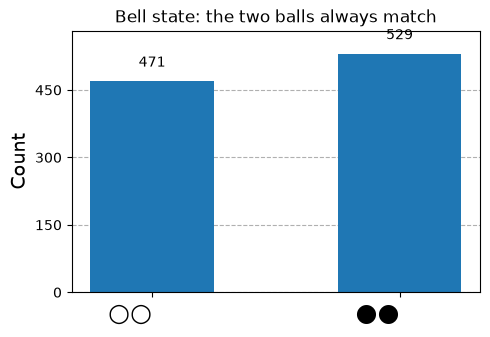

In [11]:
ball_histogram(bell, title="Bell state: the two balls always match")

Each ball on its own is a fair coin (50% ○, 50% ●), and yet they **always agree**, even if you were to carry the two balls to opposite sides of the galaxy before looking. That's **entanglement**. Einstein called it *"spooky action at a distance"*.

### What does an entangled pair look like?
* **Bloch spheres:** each qubit's arrow has **shrunk to nothing**. An entangled qubit has no state of its own; the information lives in the *pair*.
* **Q-sphere:** Qiskit's view of the *whole* state. Each dot is a configuration in the mist (size = probability, colour = the hidden sign/phase). Two dots, at opposite poles: 00 and 11.

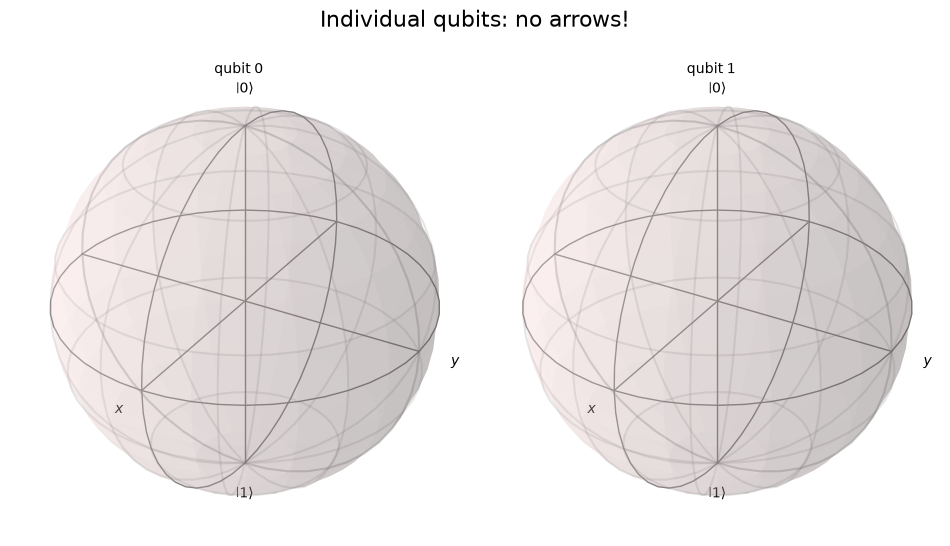

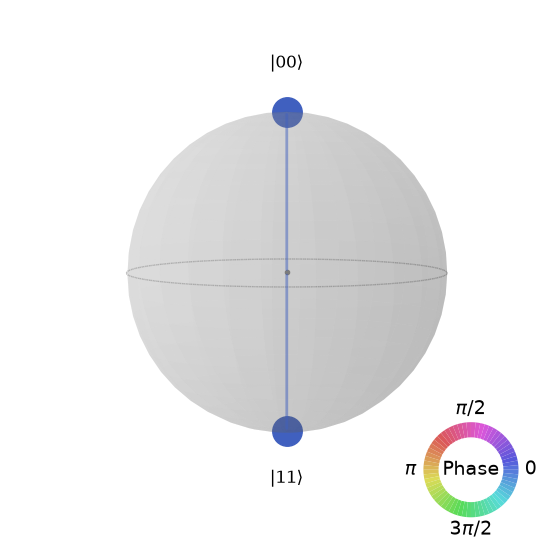

In [12]:
display(plot_bloch_multivector(Statevector(bell), title="Individual qubits: no arrows!"))
plot_state_qsphere(Statevector(bell))

## 7 · Three entangled balls: the GHZ state 🔗🔗
A Hadamard on the **middle** ball, then two C-NOTs spreading the mist up and down. Watch the mist grow step by step:

Start: **○○○**

After H on the middle ball: ☁️ mist of { **○○○ , ○●○** }

After CNOT middle → top: ☁️ mist of { **○○○ , ●●○** }

After CNOT middle → bottom: ☁️ mist of { **○○○ , ●●●** }

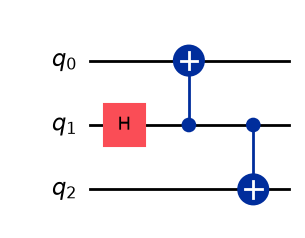

In [13]:
ghz = QuantumCircuit(3)
show_mist(ghz, "Start:")
ghz.h(1)
show_mist(ghz, "After H on the middle ball:")
ghz.cx(1, 0)
show_mist(ghz, "After CNOT middle → top:")
ghz.cx(1, 2)
show_mist(ghz, "After CNOT middle → bottom:")
ghz.draw("mpl")

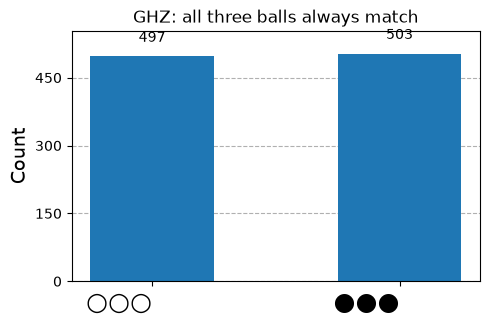

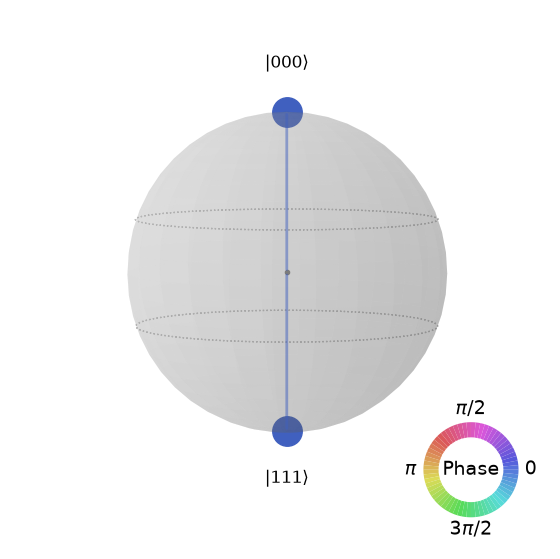

In [14]:
display(ball_histogram(ghz, title="GHZ: all three balls always match"))
plot_state_qsphere(Statevector(ghz))

### Going big 🚀
Same trick with 12 balls. There are $2^{12} = 4096$ possible colour patterns… and only **two** ever show up:

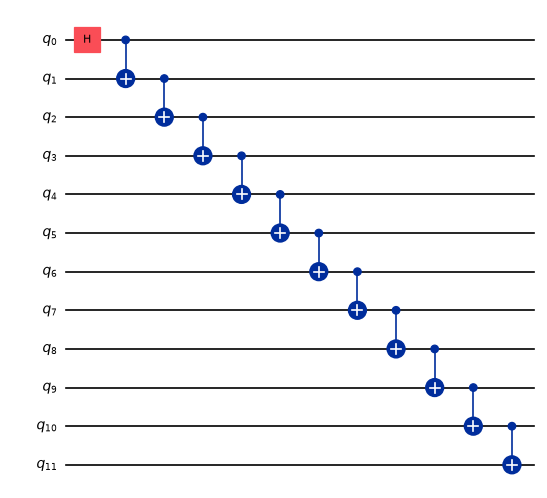

{'●●●●●●●●●●●●': 519, '○○○○○○○○○○○○': 481}


In [15]:
n = 12
big = QuantumCircuit(n)
big.h(0)
for q in range(n - 1):
    big.cx(q, q + 1)          # pass the entanglement down the line
display(big.draw("mpl", fold=-1, scale=0.6))

meas = big.measure_all(inplace=False)
counts = sampler.run([meas], shots=1000).result()[0].data.meas.get_counts()
print({qiskit_to_balls(k): v for k, v in counts.items()})

---
## 🏆 Challenges
Use `show_mist(qc)` and `ball_histogram(qc)` to check your answers.

**C1.** Make the "always opposite" pair: mist { **○● , ●○** }.

**C2.** Make a mist of **all four** two-ball patterns { ○○, ○●, ●○, ●● } (no entanglement needed!).

**C3.** Make the Bell mist with a hidden minus sign: { **○○ , −●●** }. Do the histograms look any different from the normal Bell state?

**C4. ⭐** Build a 4-ball GHZ state *starting the H on qubit 2*.

<details><summary>💡 Click for solutions</summary>

* **C1:** `qc.h(0); qc.cx(0, 1); qc.x(1)` (or start with `qc.x(1)` before the H)
* **C2:** `qc.h(0); qc.h(1)`: two independent fair coins.
* **C3:** `qc.x(0); qc.h(0); qc.cx(0, 1)` (or add `qc.z(0)` after the normal Bell circuit). The histogram is identical; the sign is hidden (but the q-sphere shows it as a different colour!).
* **C4:** `qc.h(2); qc.cx(2, 1); qc.cx(1, 0); qc.cx(2, 3)`: any tree of CNOTs that reaches every ball works.
</details>

 **○○**

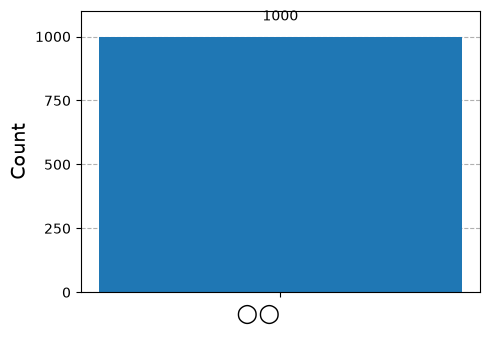

In [16]:
# ✍️ Your playground
qc = QuantumCircuit(2)

show_mist(qc)
ball_histogram(qc)

---
## ✅ Recap
| Ball game | Qiskit | Notes |
|---|---|---|
| NOT box | `qc.x(q)` | ○ ↔ ● |
| C-NOT box | `qc.cx(control, target)` | flips target if control is ● |
| SWAP box | `qc.swap(a, b)` | = three alternating C-NOTs |
| C-SWAP box | `qc.cswap(control, a, b)` | Fredkin gate |
| Hadamard box | `qc.h(q)` | makes (and un-makes!) mist |
| Bell state | `h(0); cx(0,1)` | {○○, ●●}: entangled pair |
| GHZ state | `h; cx; cx …` | {○○○, ●●●}: entangled group |

📚 **Further reading:** Terry Rudolph, *Q is for Quantum* (2017), a short, maths-free book that this whole "balls and mist" picture comes from.

👉 **Next: `04_run_on_a_real_quantum_computer.ipynb`**: let's send that Bell state to a real IBM quantum computer!